# 01. Importing Libraries

In [1]:
import os
import math
import random
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import scipy
import numpy as np
import pandas as pd

# 02. Importing Data

In [7]:
amazon = pd.read_csv('../../../IronHack/Unit 5 - EDA and Inferential Stats/amz_uk_price_prediction_dataset.csv')

In [9]:
amazon.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [44]:
amazon.shape

(2443651, 9)

# 03. Lab EDA bivariate

### Part 1: Analyzing Best-Seller Trends Across Product Categories

In [28]:
# Create a crosstab between the product category and the isBestSeller status
cross_best_seller = pd.crosstab(amazon['category'], amazon['isBestSeller'])

In [29]:
cross_best_seller

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [30]:
# Are there categories where being a best-seller is more prevalent?
# Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.
proportion_best_seller = cross_best_seller[True] / (cross_best_seller[False] + cross_best_seller[True])
proportion_best_seller = proportion_best_seller.sort_values(ascending=False)

In [31]:
proportion_best_seller

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
                                    ...   
Bedding Collections               0.000000
CPUs                              0.000000
CD, Disc & Tape Players           0.000000
Blank Media Cases & Wallets       0.000000
eBook Readers & Accessories       0.000000
Length: 296, dtype: float64

Best sellers are more prevalent in Grocery, Smart Home Security & Lighting and Health & Personal Care

In [32]:
# Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency

In [33]:
chi2_contingency(cross_best_seller)

Chi2ContingencyResult(statistic=np.float64(36540.20270061387), pvalue=np.float64(0.0), dof=295, expected_freq=array([[2.47190130e+02, 8.09870149e-01],
       [4.05371878e+03, 1.32812173e+01],
       [2.49183599e+02, 8.16401360e-01],
       [1.69145827e+03, 5.54173243e+00],
       [2.53170536e+02, 8.29463782e-01],
       [8.50214439e+03, 2.78556144e+01],
       [1.06650580e+02, 3.49419782e-01],
       [2.57157474e+02, 8.42526204e-01],
       [9.51781673e+03, 3.11832664e+01],
       [1.50008526e+04, 4.91473619e+01],
       [9.32544700e+03, 3.05530045e+01],
       [2.38219520e+02, 7.80479700e-01],
       [3.22941944e+03, 1.05805616e+01],
       [9.44704859e+03, 3.09514084e+01],
       [6.68808779e+03, 2.19122125e+01],
       [5.26275760e+02, 1.72423967e+00],
       [1.90296531e+04, 6.23469391e+01],
       [2.77191835e+03, 9.08164873e+00],
       [2.53170536e+02, 8.29463782e-01],
       [4.04674164e+02, 1.32583581e+00],
       [1.92489346e+04, 6.30653723e+01],
       [3.10482764e+03, 1.017

Pvalue = 0.0 (rounded) so it is lower than 0,05. This means that this distribution is not by chance and there is a relation between category and best seller status

In [34]:
# Compute Cramér's V to understand the strength of association between best-seller status and category.
from scipy.stats.contingency import association

In [35]:
association(cross_best_seller, method="cramer")

0.1222829439760564

The closer to 0, the weaker the association is. In this case, it is weak, even though it exists

<Axes: xlabel='category'>

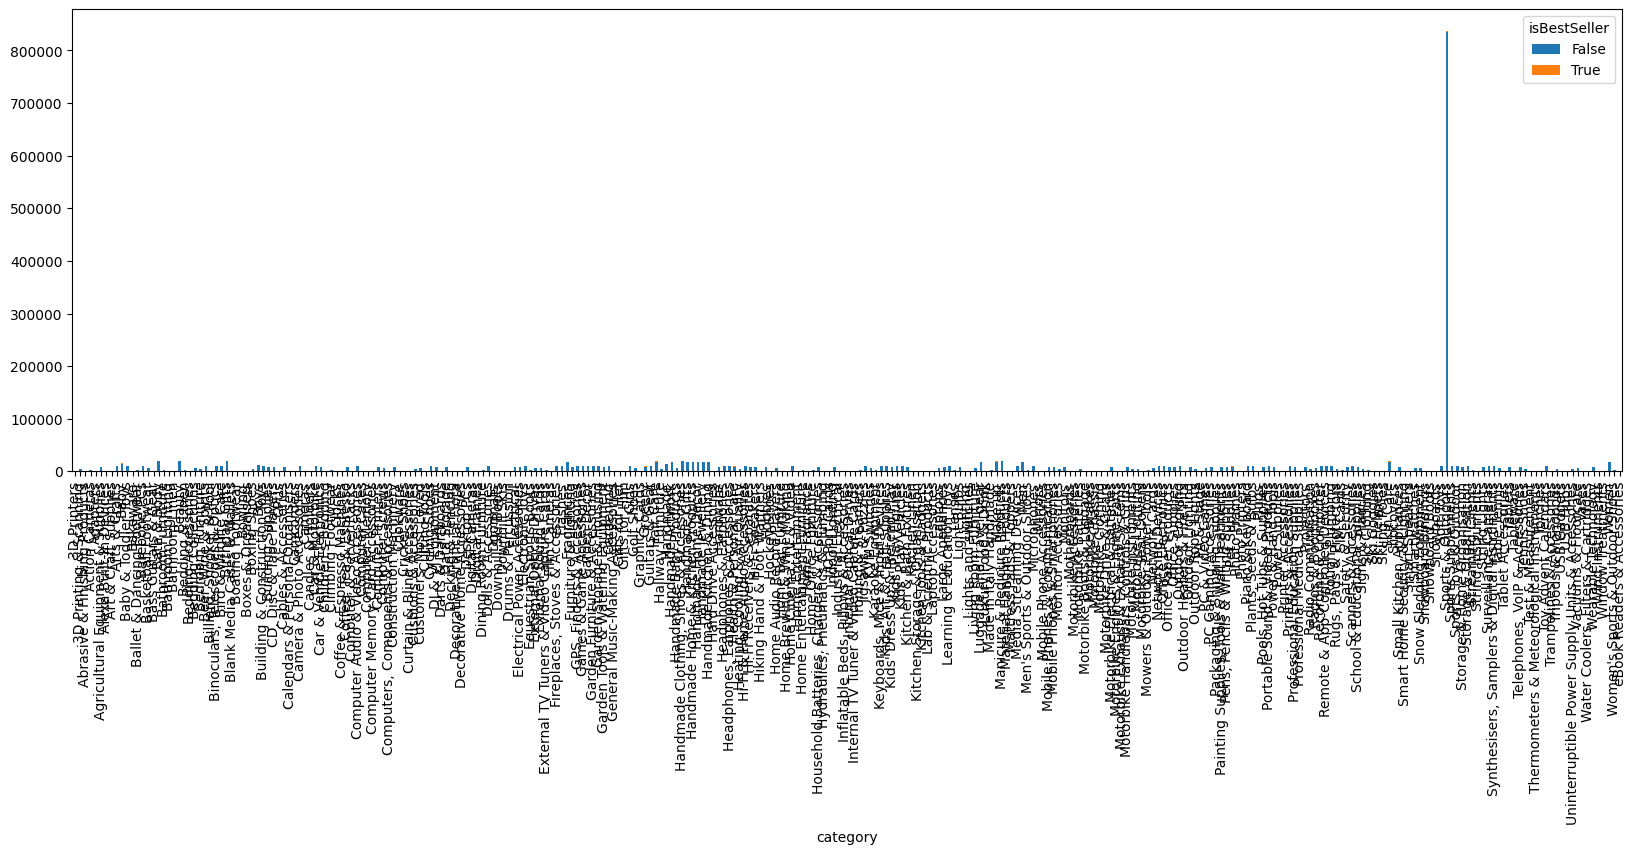

In [37]:
# Visualize the relationship between product categories and the best-seller status using a stacked bar chart.
cross_best_seller.plot(kind='bar', stacked=True, figsize=(20, 6))

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [39]:
# Preliminary Step: Remove outliers in product prices.
# For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
# Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.
Q1 = amazon['price'].quantile(0.25)
Q3 = amazon['price'].quantile(0.75)

In [40]:
IQR = Q3 - Q1

In [41]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [42]:
amazon_no_outliers = amazon[(amazon['price'] >= lower_bound) & (amazon['price'] <= upper_bound)]

In [43]:
amazon_no_outliers.shape

(2115963, 9)

In [50]:
# Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
# Which product category tends to have the highest median price? Don't filter here by top categories.
top20 = amazon_no_outliers['category'].value_counts().head(20).index

In [51]:
amazon_top20 = amazon_no_outliers[amazon_no_outliers['category'].isin(top20)]   

<Figure size 2000x600 with 0 Axes>

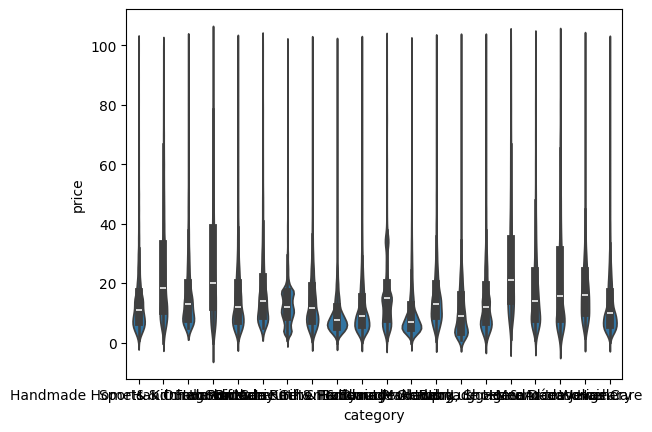

<Figure size 2000x600 with 0 Axes>

In [54]:
sns.violinplot(x='category', y='price', data=amazon_top20)
plt.figure(figsize=(20, 6))

In [58]:
# Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
# Which product category commands the highest average price? Don't filter here by top categories
top10 = amazon_no_outliers['category'].value_counts().head(10).index


In [59]:
amazon_top10 = amazon_no_outliers[amazon_no_outliers['category'].isin(top10)] 

In [61]:
amazon_top10.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors


<Axes: xlabel='category'>

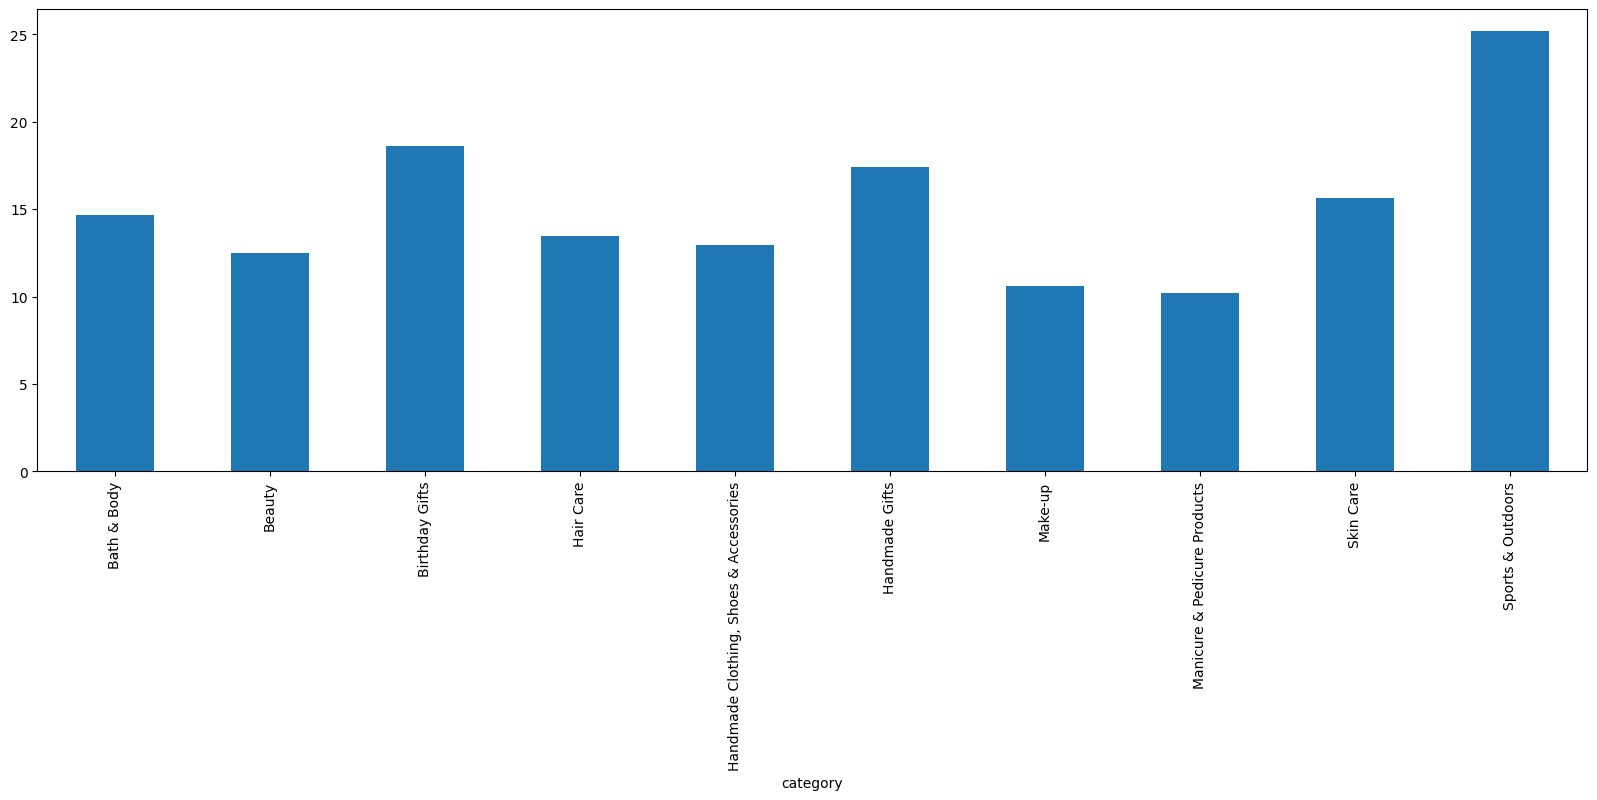

In [62]:
amazon_top10.groupby('category')['price'].mean().plot(kind='bar', stacked=True, figsize=(20, 6))

In [63]:
amazon_top10

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


C:\Users\gabri\AppData\Local\Temp\ipykernel_31240\1214336638.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='stars', data=amazon_top10, palette='Set2')


<Axes: xlabel='category', ylabel='stars'>

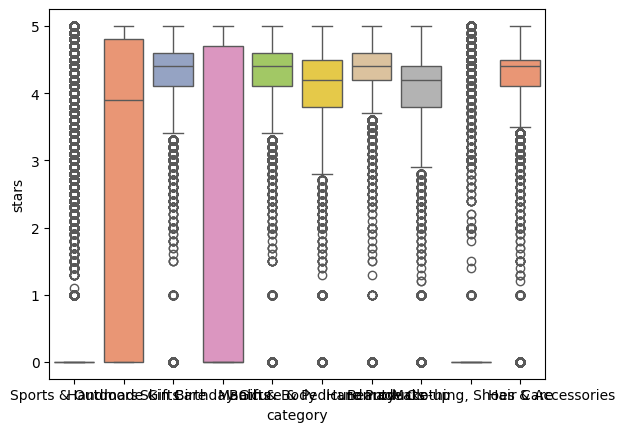

In [66]:
# Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.
sns.boxplot(x='category', y='stars', data=amazon_top10, palette='Set2')


### Part 3: Investigating the Interplay Between Product Prices and Ratings

In [67]:
# Calculate the correlation coefficient between price and stars.
# Is there a significant correlation between product price and its rating?
amazon_no_outliers['stars'].corr(amazon_no_outliers['price'])

np.float64(-0.07767299878181445)

There is no correlation between the stars rating and the price

In [68]:
amazon_no_outliers['stars'].corr(amazon_no_outliers['price'], method='spearman')

np.float64(-0.06679697280768455)

<Axes: xlabel='stars', ylabel='price'>

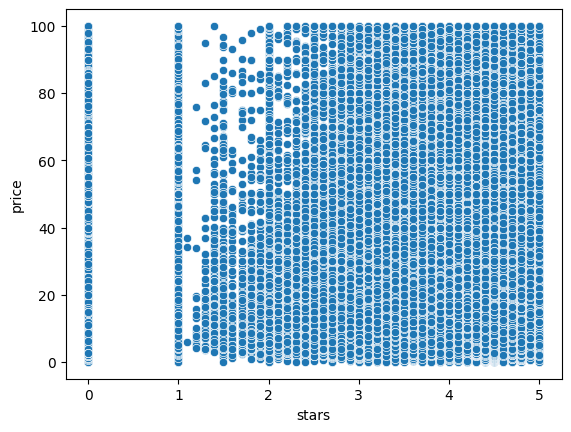

In [79]:
# Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
sns.scatterplot(x='stars', y='price', data=amazon_no_outliers)

There is no real pattern - all ratings have prices that range from 0-100. What can be seen is there there is no ratings between 0-1, and less then the rest if you observe 1-2 stars

In [ ]:
# Use a correlation heatmap to visualize correlations between all numerical variables.
amazon_numerical = amazon_no_outliers.select_dtypes('number')

In [70]:
amazon_numerical.corrwith(amazon_numerical['price']).sort_values(ascending=False)

price                1.000000
uid                  0.001717
reviews             -0.008498
boughtInLastMonth   -0.059051
stars               -0.077673
dtype: float64

In [71]:
corr_matrix = amazon_numerical.corr()

(array([0.5, 1.5, 2.5, 3.5, 4.5]),
 [Text(0.5, 0, 'uid'),
  Text(1.5, 0, 'stars'),
  Text(2.5, 0, 'reviews'),
  Text(3.5, 0, 'price'),
  Text(4.5, 0, 'boughtInLastMonth')])

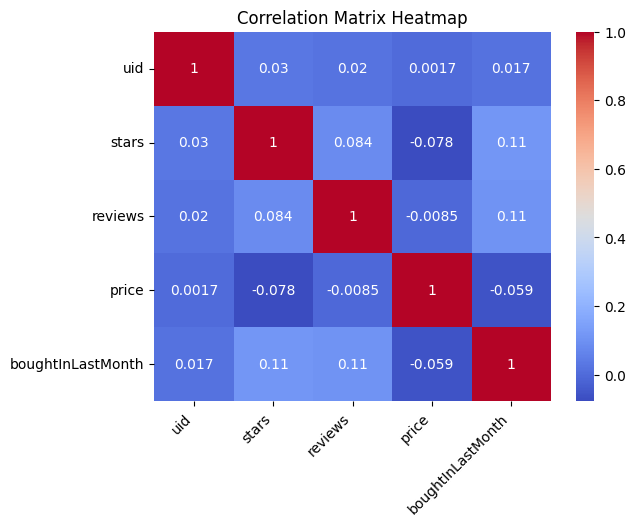

In [74]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix Heatmap')
plt.xticks(rotation=45, horizontalalignment='right') 